In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pyt
import seaborn as sns
from sklearn import svm
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv('./train_u6lujuX_CVtuZ9i.csv')

print(df)

      Loan_ID  Gender Married Dependents     Education Self_Employed  \
0    LP001002    Male      No          0      Graduate            No   
1    LP001003    Male     Yes          1      Graduate            No   
2    LP001005    Male     Yes          0      Graduate           Yes   
3    LP001006    Male     Yes          0  Not Graduate            No   
4    LP001008    Male      No          0      Graduate            No   
..        ...     ...     ...        ...           ...           ...   
609  LP002978  Female      No          0      Graduate            No   
610  LP002979    Male     Yes         3+      Graduate            No   
611  LP002983    Male     Yes          1      Graduate            No   
612  LP002984    Male     Yes          2      Graduate            No   
613  LP002990  Female      No          0      Graduate           Yes   

     ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0               5849                0.0         NaN           

In [125]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [126]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [127]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [128]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [129]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [130]:
df.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

In [131]:
df ['Property_Area'].value_counts()

Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64

In [132]:
df['Education'].value_counts()

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

In [133]:
df['Self_Employed'].value_counts()


Self_Employed
No     500
Yes     82
Name: count, dtype: int64

In [134]:
df['Gender'].value_counts()

Gender
Male      489
Female    112
Name: count, dtype: int64

In [135]:
# Checking for duplicates in the dataset
df.duplicated().sum()

np.int64(0)

In [136]:
# Checking for duplicates in the dataset
duplicates = df[df.duplicated(keep=False)]
print(duplicates)

Empty DataFrame
Columns: [Loan_ID, Gender, Married, Dependents, Education, Self_Employed, ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History, Property_Area, Loan_Status]
Index: []


In [137]:
# Dropping duplicates from the dataset
df = df.drop_duplicates()

In [138]:
print('Shape of the dataset after dropping duplicates:', df.shape)

Shape of the dataset after dropping duplicates: (614, 13)


In [139]:
print(df.columns.tolist())

['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [140]:
for column in df.columns:
    print(f"Value counts for column'{column}':")
    print(df[column].value_counts(dropna=False))

Value counts for column'Loan_ID':
Loan_ID
LP001002    1
LP001003    1
LP001005    1
LP001006    1
LP001008    1
           ..
LP002978    1
LP002979    1
LP002983    1
LP002984    1
LP002990    1
Name: count, Length: 614, dtype: int64
Value counts for column'Gender':
Gender
Male      489
Female    112
NaN        13
Name: count, dtype: int64
Value counts for column'Married':
Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64
Value counts for column'Dependents':
Dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64
Value counts for column'Education':
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64
Value counts for column'Self_Employed':
Self_Employed
No     500
Yes     82
NaN     32
Name: count, dtype: int64
Value counts for column'ApplicantIncome':
ApplicantIncome
2500    9
4583    6
6000    6
2600    6
3750    5
       ..
3232    1
2900    1
4106    1
8072    1
7583    1
Name: count, Length: 505, dtype: i

In [141]:
df['Gender'] = df['Gender'].str.upper()
print(df['Gender'])

0        MALE
1        MALE
2        MALE
3        MALE
4        MALE
        ...  
609    FEMALE
610      MALE
611      MALE
612      MALE
613    FEMALE
Name: Gender, Length: 614, dtype: str


In [142]:
df["Gender"] = df["Gender"].map({
    "FEMALE": 0,
    "MALE": 1
})

In [143]:
print(df['Gender'])

0      1.0
1      1.0
2      1.0
3      1.0
4      1.0
      ... 
609    0.0
610    1.0
611    1.0
612    1.0
613    0.0
Name: Gender, Length: 614, dtype: float64


In [144]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,0.0,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,1.0,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,1.0,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,1.0,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,0.0,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [145]:
df['Loan_Status'] = df['Loan_Status'].map({
    "N": 0,
    "Y":1,
})

In [146]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,0.0,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,1
610,LP002979,1.0,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,1
611,LP002983,1.0,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,1
612,LP002984,1.0,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,1
613,LP002990,0.0,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,0


In [147]:
df["Education"].value_counts(dropna=False)

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64

In [148]:
df["Education"] = df["Education"].map({
    "Not Graduate": 0,
    "Graduate": 1
})

In [149]:
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1.0,No,0,1,No,5849,0.0,NaN,360.0,1.0,Urban,1
1,LP001003,1.0,Yes,1,1,No,4583,1508.0,128.0,360.0,1.0,Rural,0
2,LP001005,1.0,Yes,0,1,Yes,3000,0.0,66.0,360.0,1.0,Urban,1
3,LP001006,1.0,Yes,0,0,No,2583,2358.0,120.0,360.0,1.0,Urban,1
4,LP001008,1.0,No,0,1,No,6000,0.0,141.0,360.0,1.0,Urban,1
5,LP001011,1.0,Yes,2,1,Yes,5417,4196.0,267.0,360.0,1.0,Urban,1
6,LP001013,1.0,Yes,0,0,No,2333,1516.0,95.0,360.0,1.0,Urban,1
7,LP001014,1.0,Yes,3+,1,No,3036,2504.0,158.0,360.0,0.0,Semiurban,0
8,LP001018,1.0,Yes,2,1,No,4006,1526.0,168.0,360.0,1.0,Urban,1
9,LP001020,1.0,Yes,1,1,No,12841,10968.0,349.0,360.0,1.0,Semiurban,0


In [150]:
df["Married"] = df["Married"].map ({
    "No" : 0,
    "Yes" : 1
})

In [151]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,0.0,0.0,0,1,No,2900,0.0,71.0,360.0,1.0,Rural,1
610,LP002979,1.0,1.0,3+,1,No,4106,0.0,40.0,180.0,1.0,Rural,1
611,LP002983,1.0,1.0,1,1,No,8072,240.0,253.0,360.0,1.0,Urban,1
612,LP002984,1.0,1.0,2,1,No,7583,0.0,187.0,360.0,1.0,Urban,1
613,LP002990,0.0,0.0,0,1,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,0


In [152]:
df["Property_Area"].value_counts(dropna = False)

Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64

In [153]:
df["Property_Area"] = df["Property_Area"].map ({
  "Rural" : 0,
  "Semiurban" : 1,
  "Urban" : 2
})

In [154]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,0.0,0.0,0,1,No,2900,0.0,71.0,360.0,1.0,0,1
610,LP002979,1.0,1.0,3+,1,No,4106,0.0,40.0,180.0,1.0,0,1
611,LP002983,1.0,1.0,1,1,No,8072,240.0,253.0,360.0,1.0,2,1
612,LP002984,1.0,1.0,2,1,No,7583,0.0,187.0,360.0,1.0,2,1
613,LP002990,0.0,0.0,0,1,Yes,4583,0.0,133.0,360.0,0.0,1,0


In [155]:
df["Self_Employed"] = df["Self_Employed"].map({
    "No": 0,
    "Yes": 1
})

In [156]:
df["Self_Employed"].value_counts(dropna=False)

Self_Employed
0.0    500
1.0     82
NaN     32
Name: count, dtype: int64

In [157]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,0.0,0.0,0,1,0.0,2900,0.0,71.0,360.0,1.0,0,1
610,LP002979,1.0,1.0,3+,1,0.0,4106,0.0,40.0,180.0,1.0,0,1
611,LP002983,1.0,1.0,1,1,0.0,8072,240.0,253.0,360.0,1.0,2,1
612,LP002984,1.0,1.0,2,1,0.0,7583,0.0,187.0,360.0,1.0,2,1
613,LP002990,0.0,0.0,0,1,1.0,4583,0.0,133.0,360.0,0.0,1,0


In [158]:
df["Dependents"] = df["Dependents"].replace("3+", 4)

In [159]:
df["Dependents"].value_counts(dropna= False)

Dependents
0      345
1      102
2      101
4       51
NaN     15
Name: count, dtype: int64

In [160]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,0.0,0.0,0,1,0.0,2900,0.0,71.0,360.0,1.0,0,1
610,LP002979,1.0,1.0,4,1,0.0,4106,0.0,40.0,180.0,1.0,0,1
611,LP002983,1.0,1.0,1,1,0.0,8072,240.0,253.0,360.0,1.0,2,1
612,LP002984,1.0,1.0,2,1,0.0,7583,0.0,187.0,360.0,1.0,2,1
613,LP002990,0.0,0.0,0,1,1.0,4583,0.0,133.0,360.0,0.0,1,0


<Axes: >

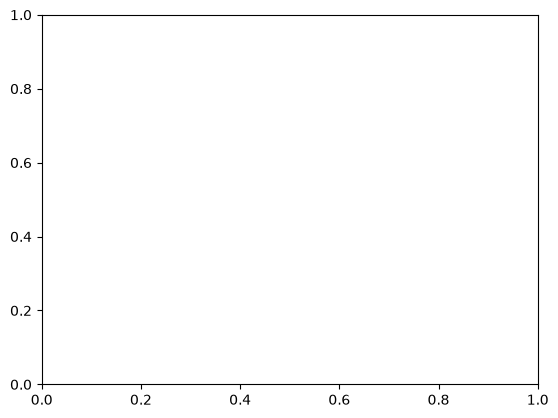

In [161]:
sns.countplot()

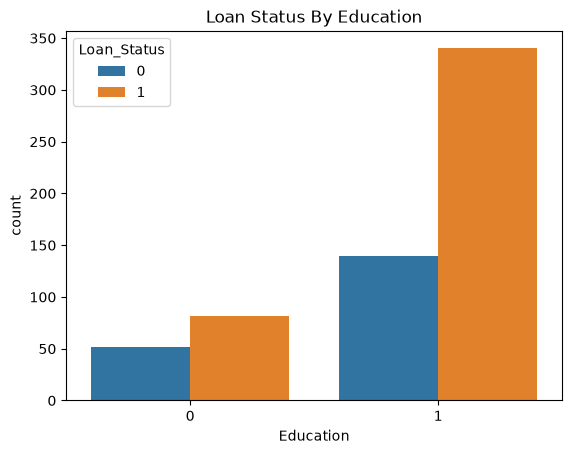

In [162]:
sns.countplot(
    data = df, 
    x = 'Education',
    hue   = 'Loan_Status',
  
)
pyt.title('Loan Status By Education')
pyt.show()

In [163]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,1.0,0.0,0,1,0.0,5849,0.0,NaN,360.0,1.0,2,1
1,LP001003,1.0,1.0,1,1,0.0,4583,1508.0,128.0,360.0,1.0,0,0
2,LP001005,1.0,1.0,0,1,1.0,3000,0.0,66.0,360.0,1.0,2,1
3,LP001006,1.0,1.0,0,0,0.0,2583,2358.0,120.0,360.0,1.0,2,1
4,LP001008,1.0,0.0,0,1,0.0,6000,0.0,141.0,360.0,1.0,2,1


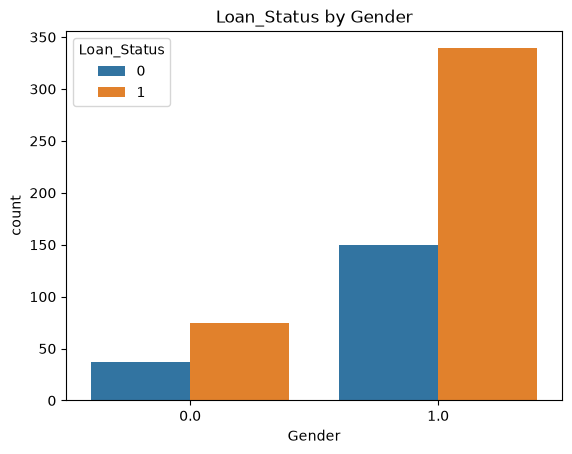

In [164]:
# Loan_Status by Gender

sns.countplot(
    x = "Gender", 
    hue = "Loan_Status", 
    data = df
    
)
pyt.title ("Loan_Status by Gender")
pyt.show()



In [165]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [166]:
print("Rows before removing missing values:", len(df))
print("Rows with no missing values:", len(df.dropna()))

Rows before removing missing values: 614
Rows with no missing values: 480


In [167]:
df.dtypes

Loan_ID                  str
Gender               float64
Married              float64
Dependents            object
Education              int64
Self_Employed        float64
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area          int64
Loan_Status            int64
dtype: object

In [168]:
df["Gender"].value_counts(dropna=False) 

Gender
1.0    489
0.0    112
NaN     13
Name: count, dtype: int64

In [169]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [170]:
df['Gender'].isnull().sum()

np.int64(0)

In [171]:
df['Gender'].value_counts()

Gender
1.0    502
0.0    112
Name: count, dtype: int64

In [172]:
df["Married"].value_counts(dropna=False) 

Married
1.0    398
0.0    213
NaN      3
Name: count, dtype: int64

In [173]:
df["Married"] = df["Married"].fillna(
    df["Married"].mode()[0]
)

In [174]:
df["Married"].value_counts() 

Married
1.0    401
0.0    213
Name: count, dtype: int64

In [175]:
df["Dependents"].value_counts(dropna=False)

Dependents
0      345
1      102
2      101
4       51
NaN     15
Name: count, dtype: int64

In [176]:
df["Dependents"] = df["Dependents"].fillna(
    df["Dependents"].mode()[0]
)

In [177]:
df["Dependents"].value_counts(dropna = False)

Dependents
0    360
1    102
2    101
4     51
Name: count, dtype: int64

In [178]:
df["Self_Employed"].value_counts(dropna=False)

Self_Employed
0.0    500
1.0     82
NaN     32
Name: count, dtype: int64

In [179]:
df["Self_Employed"] =df["Self_Employed"].fillna(
    df["Self_Employed"] .mode()[0]
)

In [180]:
df["Self_Employed"].value_counts()

Self_Employed
0.0    532
1.0     82
Name: count, dtype: int64

In [181]:
df["Credit_History"].value_counts(dropna=False)

Credit_History
1.0    475
0.0     89
NaN     50
Name: count, dtype: int64

In [182]:
df["Credit_History"] = df["Credit_History"].fillna(
    df["Credit_History"].mode()[0]
)

In [183]:
df['Credit_History'].value_counts(dropna = False)

Credit_History
1.0    525
0.0     89
Name: count, dtype: int64

In [184]:
df["LoanAmount"].isnull().sum()

np.int64(22)

In [185]:
df["LoanAmount"].median()

np.float64(128.0)

In [186]:
df["LoanAmount"] = df["LoanAmount"].fillna(
    df["LoanAmount"].median()
)

In [187]:
df["LoanAmount"].value_counts(dropna=False)

LoanAmount
128.0    33
120.0    20
110.0    17
100.0    15
187.0    12
         ..
292.0     1
142.0     1
350.0     1
496.0     1
253.0     1
Name: count, Length: 203, dtype: int64

In [188]:
df["Loan_Amount_Term"].isnull().sum()

np.int64(14)

In [189]:
df["Loan_Amount_Term"].median()

np.float64(360.0)

In [190]:
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(
    df["Loan_Amount_Term"].median()
)

In [191]:
df["Loan_Amount_Term"].value_counts(dropna=False)

Loan_Amount_Term
360.0    526
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [192]:
df["Loan_Amount_Term"].isnull().sum()

np.int64(0)

In [193]:
df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [194]:
df.dtypes

Loan_ID                  str
Gender               float64
Married              float64
Dependents            object
Education              int64
Self_Employed        float64
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area          int64
Loan_Status            int64
dtype: object

In [195]:
df["Dependents"] = pd.to_numeric(
   df["Dependents"]
)

In [196]:
df.dtypes

Loan_ID                  str
Gender               float64
Married              float64
Dependents             int64
Education              int64
Self_Employed        float64
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area          int64
Loan_Status            int64
dtype: object

In [197]:
X = df.drop(columns=["Loan_ID", "Loan_Status"])
Y = df["Loan_Status"]

In [198]:
X.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,1.0,0.0,0,1,0.0,5849,0.0,128.0,360.0,1.0,2
1,1.0,1.0,1,1,0.0,4583,1508.0,128.0,360.0,1.0,0
2,1.0,1.0,0,1,1.0,3000,0.0,66.0,360.0,1.0,2
3,1.0,1.0,0,0,0.0,2583,2358.0,120.0,360.0,1.0,2
4,1.0,0.0,0,1,0.0,6000,0.0,141.0,360.0,1.0,2


In [199]:
Y.head()

0    1
1    0
2    1
3    1
4    1
Name: Loan_Status, dtype: int64

In [200]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [201]:
X.shape

(614, 11)

In [202]:
X_train.shape

(491, 11)

In [203]:
X_test.shape

(123, 11)

In [204]:
print("Original data:", X.shape)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Original data: (614, 11)
Training data: (491, 11)
Testing data: (123, 11)


In [205]:
scaler = StandardScaler()

In [206]:
scaler.fit(X_train)

StandardScaler()

In [207]:
X_train = scaler.transform(X_train)

In [208]:
type(X_train)

numpy.ndarray

In [209]:
print(X_train.shape)
print(X_train[:5])

(491, 11)
[[ 0.46405445 -1.38033526 -0.69243928  0.54046763 -0.39407375 -0.352802
  -0.56322811 -1.13158849  0.28069139  0.39751587  1.22203919]
 [ 0.46405445  0.72446168  0.1429113   0.54046763 -0.39407375 -0.3433464
  -0.56322811 -0.59230932  0.28069139  0.39751587 -0.04382841]
 [ 0.46405445  0.72446168  0.97826188  0.54046763 -0.39407375 -0.33947116
   0.05040502  0.04075753  0.28069139 -2.51562283 -1.30969601]
 [ 0.46405445  0.72446168  0.1429113  -1.85024956 -0.39407375 -0.44596289
  -0.02495343 -0.3930105  -2.48676788 -2.51562283 -1.30969601]
 [ 0.46405445  0.72446168 -0.69243928  0.54046763 -0.39407375 -0.45107822
   0.23449496  0.04075753  0.28069139  0.39751587 -0.04382841]]


In [210]:
print("X_train type:", type(X_train))
print("X_train shape:", X_train.shape)
print("Largest absolute value:", abs(X_train).max())

X_train type: <class 'numpy.ndarray'>
X_train shape: (491, 11)
Largest absolute value: 14.38896572077029


In [211]:
print("Training data type:", type(X_train))
print("Training data shape:", X_train.shape)
print("Largest absolute value:", abs(X_train).max())

Training data type: <class 'numpy.ndarray'>
Training data shape: (491, 11)
Largest absolute value: 14.38896572077029


In [212]:
print("Scaler mean shape:", scaler.mean_.shape)
print("Scaler scale shape:", scaler.scale_.shape)

Scaler mean shape: (11,)
Scaler scale shape: (11,)


In [213]:
# 1. Split the original data again
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

# 2. Create a fresh scaler
scaler = StandardScaler()

# 3. Learn from the training data
scaler.fit(X_train)

# 4. Scale the training data
X_train = scaler.transform(X_train)

# 5. Scale the testing data using the same scaler
X_test = scaler.transform(X_test)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Largest absolute training value:", abs(X_train).max())

Training shape: (491, 11)
Testing shape: (123, 11)
Largest absolute training value: 14.38896572077029


In [214]:
import numpy as np

feature_names = X.columns

largest_values = pd.Series(
    abs(X_train).max(axis=0),
    index=feature_names
)

print(largest_values.sort_values(ascending=False))


CoapplicantIncome    14.388966
ApplicantIncome      11.698590
LoanAmount            6.488661
Loan_Amount_Term      5.069730
Dependents            2.648963
Self_Employed         2.537596
Credit_History        2.515623
Gender                2.154920
Education             1.850250
Married               1.380335
Property_Area         1.309696
dtype: float64


In [215]:
print("Feature averages:")
print(np.round(X_train.mean(axis=0), 2))

print("\nFeature standard deviations:")
print(np.round(X_train.std(axis=0), 2))


Feature averages:
[ 0.  0.  0.  0. -0. -0.  0. -0. -0. -0. -0.]

Feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [216]:
print("Training labels:", Y_train.shape)
print("Testing labels:", Y_test.shape)
print("\nTraining loan decisions:")
print(Y_train.value_counts())

Training labels: (491,)
Testing labels: (123,)

Training loan decisions:
Loan_Status
1    337
0    154
Name: count, dtype: int64


In [217]:
from sklearn.linear_model import LogisticRegression


In [218]:
model = LogisticRegression()

In [219]:
model.fit(X_train, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [220]:
Y_pred = model.predict(X_test)

In [221]:
print(Y_pred[:10])

[0 1 1 1 1 1 1 1 1 1]


In [222]:
print(Y_test[:10].to_numpy())

[0 1 1 1 1 0 1 1 1 1]


In [223]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(Y_test, Y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 86.1788617886179 %


In [224]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, Y_pred)

print(cm)

[[22 16]
 [ 1 84]]


In [225]:
from sklearn.metrics import classification_report

print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



In [226]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

importance = importance.sort_values(
    by="Coefficient",
    ascending=False
)

print(importance)

              Feature  Coefficient
9      Credit_History     1.233195
1             Married     0.262960
3           Education     0.182971
2          Dependents     0.111804
10      Property_Area     0.048337
8    Loan_Amount_Term     0.003964
5     ApplicantIncome    -0.009755
7          LoanAmount    -0.037612
4       Self_Employed    -0.070971
0              Gender    -0.090926
6   CoapplicantIncome    -0.151582


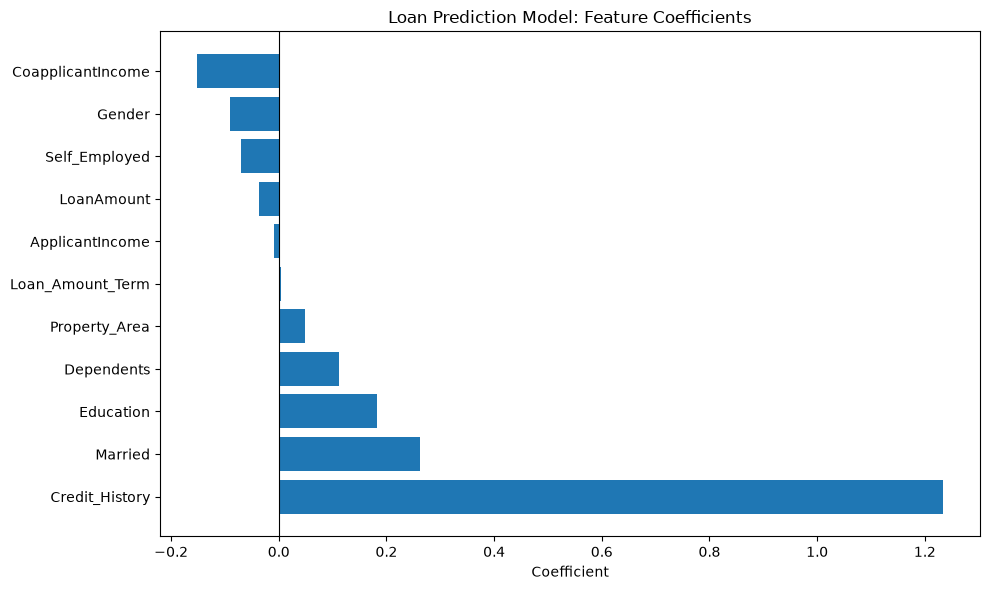

In [227]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)
plt.xlabel("Coefficient")
plt.title("Loan Prediction Model: Feature Coefficients")
plt.tight_layout()
plt.show()

In [228]:
new_applicant = pd.DataFrame([{
    "Gender": 1,
    "Married": 0,
    "Dependents": 0,
    "Education": 1,
    "Self_Employed": 0,
    "ApplicantIncome": 5000,
    "CoapplicantIncome": 2000,
    "LoanAmount": 120,
    "Loan_Amount_Term": 360,
    "Credit_History": 1,
    "Property_Area": 2
}])

print(new_applicant)

   Gender  Married  Dependents  Education  Self_Employed  ApplicantIncome  \
0       1        0           0          1              0             5000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0               2000         120               360               1   

   Property_Area  
0              2  


In [229]:
new_applicant_scaled = scaler.transform(new_applicant)

print(new_applicant_scaled)

[[ 0.46405445 -1.38033526 -0.69243928  0.54046763 -0.39407375 -0.08215488
   0.15447146 -0.31094628  0.28069139  0.39751587  1.22203919]]


In [230]:
print(type(new_applicant))
print(type(new_applicant_scaled))

<class 'pandas.DataFrame'>
<class 'numpy.ndarray'>


In [231]:
print("Scaler features:")
print(scaler.feature_names_in_)

print("\nNew applicant columns:")
print(new_applicant.columns.tolist())

Scaler features:
['Gender' 'Married' 'Dependents' 'Education' 'Self_Employed'
 'ApplicantIncome' 'CoapplicantIncome' 'LoanAmount' 'Loan_Amount_Term'
 'Credit_History' 'Property_Area']

New applicant columns:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']


In [232]:
new_applicant_scaled_df = pd.DataFrame(
    new_applicant_scaled,
    columns=new_applicant.columns
)

new_prediction = model.predict(new_applicant_scaled_df)

print("Loan Prediction:", new_prediction[0])

Loan Prediction: 1


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [233]:
print("Target values:", Y.unique())
print("Model classes:", model.classes_)

Target values: [1 0]
Model classes: [0 1]


In [234]:
print("Y_train data type:", Y_train.dtype)
print("Y_train sample:")
print(Y_train.head())

print("\nModel classes:", model.classes_)

Y_train data type: int64
Y_train sample:
154    1
239    1
448    0
471    0
273    1
Name: Loan_Status, dtype: int64

Model classes: [0 1]


In [235]:
print("Model classes:", model.classes_)
print("Prediction array:", model.predict(new_applicant_scaled_df))
print("Prediction data type:", model.predict(new_applicant_scaled_df).dtype)

Model classes: [0 1]
Prediction array: [1]
Prediction data type: int64


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [236]:
new_prediction = model.predict(new_applicant_scaled_df)[0]

if new_prediction == 1:
    print("Loan Prediction: Approved")
else:
    print("Loan Prediction: Rejected")

Loan Prediction: Approved


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [237]:

from sklearn.metrics import accuracy_score

Y_pred = model.predict(X_test)
accuracy = accuracy_score(Y_test, Y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")


Model Accuracy: 86.18%


[[22 16]
 [ 1 84]]


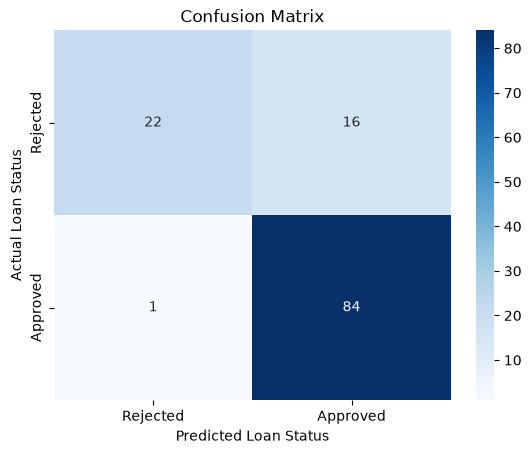

In [238]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(Y_test, Y_pred)

print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.xlabel("Predicted Loan Status")
plt.ylabel("Actual Loan Status")
plt.title("Confusion Matrix")
plt.show()


In [239]:

from sklearn.metrics import classification_report

print(classification_report(
    Y_test,
    Y_pred,
    target_names=["Rejected", "Approved"]
))


              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



In [240]:

import pandas as pd

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients["Absolute_Importance"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    by="Absolute_Importance",
    ascending=False
)

print(coefficients)


              Feature  Coefficient  Absolute_Importance
9      Credit_History     1.233195             1.233195
1             Married     0.262960             0.262960
3           Education     0.182971             0.182971
6   CoapplicantIncome    -0.151582             0.151582
2          Dependents     0.111804             0.111804
0              Gender    -0.090926             0.090926
4       Self_Employed    -0.070971             0.070971
10      Property_Area     0.048337             0.048337
7          LoanAmount    -0.037612             0.037612
5     ApplicantIncome    -0.009755             0.009755
8    Loan_Amount_Term     0.003964             0.003964


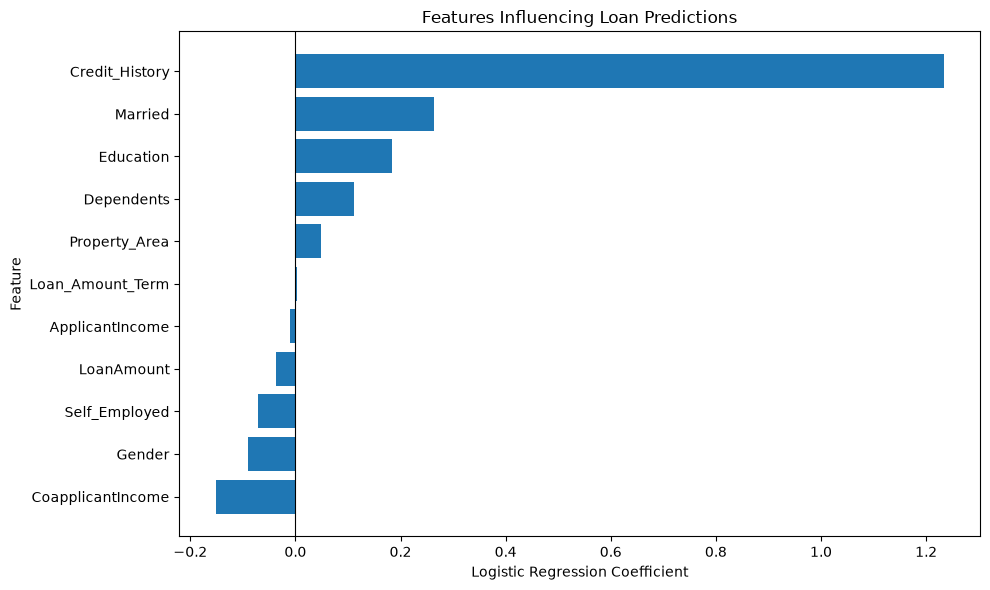

In [241]:

import matplotlib.pyplot as plt

plot_data = coefficients.sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"]
)

plt.axvline(x=0, color="black", linewidth=0.8)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Features Influencing Loan Predictions")
plt.tight_layout()
plt.show()

In [242]:

new_applicants = pd.DataFrame([
    {
        "Gender": 1,
        "Married": 0,
        "Dependents": 0,
        "Education": 1,
        "Self_Employed": 0,
        "ApplicantIncome": 5000,
        "CoapplicantIncome": 2000,
        "LoanAmount": 120,
        "Loan_Amount_Term": 360,
        "Credit_History": 1,
        "Property_Area": 2
    },
    {
        "Gender": 0,
        "Married": 1,
        "Dependents": 2,
        "Education": 0,
        "Self_Employed": 1,
        "ApplicantIncome": 2500,
        "CoapplicantIncome": 0,
        "LoanAmount": 180,
        "Loan_Amount_Term": 360,
        "Credit_History": 0,
        "Property_Area": 0
    },
    {
        "Gender": 1,
        "Married": 1,
        "Dependents": 1,
        "Education": 1,
        "Self_Employed": 0,
        "ApplicantIncome": 8000,
        "CoapplicantIncome": 3000,
        "LoanAmount": 200,
        "Loan_Amount_Term": 360,
        "Credit_History": 1,
        "Property_Area": 1
    }
])

# Apply the same scaler used during training
applicants_scaled = scaler.transform(new_applicants)

# Predict each applicant's loan status
predictions = model.predict(applicants_scaled)

# Display the results
new_applicants["Prediction"] = [
    "Approved" if prediction == 1 else "Rejected"
    for prediction in predictions
]

print(new_applicants[["ApplicantIncome", "Credit_History", "Prediction"]])


   ApplicantIncome  Credit_History Prediction
0             5000               1   Approved
1             2500               0   Rejected
2             8000               1   Approved


In [243]:

# Get the probability of each prediction
probabilities = model.predict_proba(applicants_scaled)

# Add the probabilities to our results table
new_applicants["Approval_Probability"] = probabilities[:, 1] * 100
new_applicants["Rejection_Probability"] = probabilities[:, 0] * 100

# Display the results
print(new_applicants[
    [
        "ApplicantIncome",
        "Credit_History",
        "Prediction",
        "Approval_Probability",
        "Rejection_Probability"
    ]
].round(2))


   ApplicantIncome  Credit_History Prediction  Approval_Probability  \
0             5000               1   Approved                 72.96   
1             2500               0   Rejected                  9.09   
2             8000               1   Approved                 81.52   

   Rejection_Probability  
0                  27.04  
1                  90.91  
2                  18.48  


In [244]:

import joblib

# Save the trained model
joblib.dump(model, "loan_prediction_model.pkl")

# Save the scaler used to prepare the data
joblib.dump(scaler, "loan_scaler.pkl")

print("Model and scaler saved successfully!")


Model and scaler saved successfully!


In [245]:

import joblib

# Load the saved model and scaler
loaded_model = joblib.load("loan_prediction_model.pkl")
loaded_scaler = joblib.load("loan_scaler.pkl")

print("Saved model loaded successfully!")
print("Saved scaler loaded successfully!")


Saved model loaded successfully!
Saved scaler loaded successfully!


In [246]:

# Prepare the first applicant using the saved scaler
applicant_scaled = loaded_scaler.transform(
    new_applicants.drop(
        columns=["Prediction", "Approval_Probability", "Rejection_Probability"],
        errors="ignore"
    ).iloc[[0]]
)

# Make a prediction using the loaded model
prediction = loaded_model.predict(applicant_scaled)[0]
probability = loaded_model.predict_proba(applicant_scaled)[0, 1] * 100

if prediction == 1:
    print("Loan Prediction: Approved")
else:
    print("Loan Prediction: Rejected")

print(f"Approval Probability: {probability:.2f}%")


Loan Prediction: Approved
Approval Probability: 72.96%
